# Batik Lestari — Q3 2026 Sales Analysis (FGSeara Group 1)

**Portfolio-ready copy of the original group notebook.** My primary contribution: data visualizations in Section 5 (Matplotlib & Seaborn). Data preparation, analysis, and recommendations were completed collaboratively.

**Portfolio adjustments**: corrected local CSV path, income calculation to use cleaned data, P4 denominator, timestamp matching warning, and clarified overall daily average. The original group deliverable was preserved separately by the team.

To run: install pandas, numpy, matplotlib, seaborn; open this notebook from the repository root so the path `data/batik_lestari_q3_sales.csv` resolves.

# **1. Kenalan dengan Data**

In [ ]:
# Import seluruh library yang akan digunakan
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Baca file .csv
df = pd.read_csv("data/batik_lestari_q3_sales.csv")
print("data sudah dibuka!")

data sudah dibuka!


In [ ]:
# Fungsi untuk menampilkan seluruh kolom beserta 5 data teratasnya apabila tidak ada angka di dalam tanda ()
df.head()

,id_pesanan,tanggal_pesanan,channel,kota_pembeli,kategori,produk,harga_satuan,jumlah,diskon_persen,metode_bayar,status_pesanan,rating
0,BL-00001,2026-07-01,Shopee,Yogyakarta,Kemeja Pria,Kemeja Batik Parang Lengan Pendek,185000,1,5,Transfer Bank,Selesai,5.0
1,BL-00002,2026-07-01,Tokopedia,Pekalongan,Aksesoris,Scarf Batik Sutra,95000,1,10,COD,Selesai,4.0
2,BL-00003,2026-07-01,Toko Offline,Pekalongan,Kemeja Pria,Kemeja Batik Kawung Slim Fit,215000,1,10,QRIS,Selesai,5.0
3,BL-00004,2026-07-01,Toko Offline,Semarang,Kemeja Pria,Kemeja Batik Mega Mendung Lengan Panjang,245000,3,0,QRIS,Selesai,4.0
4,BL-00005,2026-07-01,Toko Offline,Jakarta,Outer,Outer Batik Kimono,159000,2,5,Kartu Debit,Selesai,4.0


In [ ]:
# Menampilkan jumlah baris dan kolom
df.shape

(1206, 12)

In [ ]:
# Menampilkan spesifikasi data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1206 entries, 0 to 1205
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_pesanan       1206 non-null   object 
 1   tanggal_pesanan  1206 non-null   object 
 2   channel          1206 non-null   object 
 3   kota_pembeli     1175 non-null   object 
 4   kategori         1206 non-null   object 
 5   produk           1206 non-null   object 
 6   harga_satuan     1206 non-null   int64  
 7   jumlah           1206 non-null   int64  
 8   diskon_persen    1206 non-null   int64  
 9   metode_bayar     1206 non-null   object 
 10  status_pesanan   1206 non-null   object 
 11  rating           932 non-null    float64
dtypes: float64(1), int64(3), object(8)
memory usage: 113.2+ KB


In [ ]:
# Tampilkan summary data secara keseluruhan
df.describe()

,harga_satuan,jumlah,diskon_persen,rating
count,1206.000000,1206.000000,1206.000000,932.000000
mean,167325.041459,1.862355,6.546434,4.097639
std,92315.517879,1.498312,6.978978,1.014458
min,35000.000000,1.000000,0.000000,1.000000
25%,95000.000000,1.000000,0.000000,4.000000
50%,185000.000000,1.000000,5.000000,4.000000
75%,215000.000000,2.000000,10.000000,5.000000
max,450000.000000,10.000000,25.000000,5.000000


# **2. Membersihkan Data**

**2.1 Cek dan menghilangkan data duplicate**

In [ ]:
df[df.duplicated(keep=False)].head(6)

,id_pesanan,tanggal_pesanan,channel,kota_pembeli,kategori,produk,harga_satuan,jumlah,diskon_persen,metode_bayar,status_pesanan,rating
73,BL-00074,2026-07-07,Shopee,Bandung,Dress Wanita,Dress Batik Truntum Casual,199000,1,20,COD,Selesai,3.0
74,BL-00074,2026-07-07,Shopee,Bandung,Dress Wanita,Dress Batik Truntum Casual,199000,1,20,COD,Selesai,3.0
127,BL-00127,2026-07-11,TikTok Shop,Surabaya,Dress Wanita,Dress Batik Truntum Casual,199000,1,10,E-Wallet,Selesai,4.0
128,BL-00127,2026-07-11,TikTok Shop,Surabaya,Dress Wanita,Dress Batik Truntum Casual,199000,1,10,E-Wallet,Selesai,4.0
162,BL-00161,2026-07-14,shopee,Denpasar,Kemeja Pria,Kemeja Batik Parang Lengan Pendek,185000,1,5,Transfer Bank,Selesai,4.0
163,BL-00161,2026-07-14,shopee,Denpasar,Kemeja Pria,Kemeja Batik Parang Lengan Pendek,185000,1,5,Transfer Bank,Selesai,4.0


In [ ]:
df_bersih = df.drop_duplicates().copy()
print("Sebelum:", df.shape)
print("Sesudah:", df_bersih.shape)

Sebelum: (1206, 12)
Sesudah: (1180, 12)


**2.2 Memperbaiki inkonsistensi data**

In [ ]:
#variabel channel
df_bersih["channel"] = df_bersih["channel"].str.strip().str.title()
df_bersih["channel"].unique()

array(['Shopee', 'Tokopedia', 'Toko Offline', 'Tiktok Shop'], dtype=object)

In [ ]:
#variabel kota pembeli
df_bersih["kota_pembeli"] = df_bersih["kota_pembeli"].str.strip().str.title()
df_bersih["kota_pembeli"].unique()

array(['Yogyakarta', 'Pekalongan', 'Semarang', 'Jakarta', 'Surabaya',
       'Makassar', 'Medan', 'Denpasar', 'Bandung', nan], dtype=object)

In [ ]:
#variabel kategori
df_bersih["kategori"] = df_bersih["kategori"].str.strip().str.title()
df_bersih["kategori"].unique()

array(['Kemeja Pria', 'Aksesoris', 'Outer', 'Dress Wanita', 'Kain Batik'],
      dtype=object)

In [ ]:
#variabel produk
df_bersih["produk"] = df_bersih["produk"].str.strip().str.title()
df_bersih["produk"].unique()

array(['Kemeja Batik Parang Lengan Pendek', 'Scarf Batik Sutra',
       'Kemeja Batik Kawung Slim Fit',
       'Kemeja Batik Mega Mendung Lengan Panjang', 'Outer Batik Kimono',
       'Masker Batik Isi 3', 'Dress Batik Sogan Midi',
       'Dress Batik Truntum Casual', 'Kain Batik Cap Motif Jlamprang',
       'Tote Bag Batik', 'Kain Batik Tulis Pekalongan',
       'Blazer Batik Kombinasi'], dtype=object)

In [ ]:
# variabel metode bayar
df_bersih["metode_bayar"].unique() # Semua penulisan sudah benar, jadi tidak perlu diubah

array(['Transfer Bank', 'COD', 'QRIS', 'Kartu Debit', 'Paylater',
       'E-Wallet', 'Tunai'], dtype=object)

In [ ]:
# Periksa nilai-nilai pada status_pesanan
df_bersih["status_pesanan"].unique()

array(['Selesai', 'Dibatalkan', 'selesai', 'Dikembalikan'], dtype=object)

In [ ]:
# Perbaiki nilai-nilai pada status_pesanan
df_bersih["status_pesanan"]= df_bersih["status_pesanan"].str.title()

In [ ]:
# Periksa lagi nilai-nilai pada status_pesanan
df_bersih["status_pesanan"].unique() # Sudah benar

array(['Selesai', 'Dibatalkan', 'Dikembalikan'], dtype=object)

**2.3 Ubah teks menjadi tanggal**

In [ ]:
df_bersih["tanggal_pesanan"] = pd.to_datetime(df_bersih["tanggal_pesanan"])
df_bersih.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1180 entries, 0 to 1205
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_pesanan       1180 non-null   object        
 1   tanggal_pesanan  1180 non-null   datetime64[ns]
 2   channel          1180 non-null   object        
 3   kota_pembeli     1149 non-null   object        
 4   kategori         1180 non-null   object        
 5   produk           1180 non-null   object        
 6   harga_satuan     1180 non-null   int64         
 7   jumlah           1180 non-null   int64         
 8   diskon_persen    1180 non-null   int64         
 9   metode_bayar     1180 non-null   object        
 10  status_pesanan   1180 non-null   object        
 11  rating           912 non-null    float64       
dtypes: datetime64[ns](1), float64(1), int64(3), object(7)
memory usage: 119.8+ KB


**2.4 Menangani rating kosong**

Rating yang kosong dibiarkan kosong, karena pelanggan memang boleh tidak memberi rating.

In [ ]:
print("Rata rata rating:", round(df_bersih["rating"].mean(), 2))

Rata rata rating: 4.09


**2.5 Menangani kota pembeli yang kosong**

In [ ]:
df_bersih["kota_pembeli"] = df_bersih["kota_pembeli"].fillna("Unknown")
print("kota pembeli kosong telah diubah menjadi Unknown!")

kota pembeli kosong telah diubah menjadi Unknown!


**2.6 Menyaring data yang berstatus 'Selesai' saja**

In [ ]:
# Membuat df_analisis dengan menyaring data yang berstatus 'Selesai' saja
df_analisis = df_bersih[df_bersih["status_pesanan"] == "Selesai"].copy()

# Mengecek ukuran data setelah disaring
print("Ukuran data df_bersih (untuk P4)  :", df_bersih.shape)
print("Ukuran data df_analisis (P1-P6)   :", df_analisis.shape)


Ukuran data df_bersih (untuk P4)  : (1180, 12)
Ukuran data df_analisis (P1-P6)   : (1062, 12)


# **3. Menyiapkan Kolom Baru**

In [ ]:
# Buat kolom pendapatan_bersih = harga_satuan x jumlah x (1 - diskon_persen / 100)
df_bersih["pendapatan_bersih"] = (df_bersih["harga_satuan"] * df_bersih["jumlah"] * (1 - df_bersih["diskon_persen"] / 100))

display(df_bersih[["harga_satuan", "jumlah", "diskon_persen", "pendapatan_bersih"]].head())

,harga_satuan,jumlah,diskon_persen,pendapatan_bersih
0,185000,1,5,175750.0
1,95000,1,10,85500.0
2,215000,1,10,193500.0
3,245000,3,0,735000.0
4,159000,2,5,302100.0


In [ ]:
# Buat kolom bulan dari tanggal pesanan. Petunjuk: df["tanggal_pesanan"].dt.month.
df_bersih["bulan"] = df_bersih["tanggal_pesanan"].dt.month

display(df_bersih[["tanggal_pesanan", "bulan"]].head())

,tanggal_pesanan,bulan
0,2026-07-01,7
1,2026-07-01,7
2,2026-07-01,7
3,2026-07-01,7
4,2026-07-01,7


In [ ]:
df_bersih.shape

(1180, 14)

### Definisi Pendapatan

Kolom pendapatan_bersih dihitung dari harga satuan dikalikan
jumlah item, kemudian dikurangi diskon.

Hanya pesanan berstatus Selesai yang dihitung sebagai
pendapatan. Pesanan Dibatalkan dan Dikembalikan tidak
dihitung karena penjualannya tidak dipertahankan.

Nilai ini merupakan penjualan setelah diskon, bukan laba,
karena belum dikurangi biaya platform, ongkir, pajak,
dan harga pokok produk.

Kolom bulan diambil dari tanggal_pesanan untuk membantu
analisis penjualan Juli, Agustus, dan September.

# **4. Menjawab Pertanyaan Bisnis Bu Ratna**

In [ ]:
# P1. Channel mana yang menghasilkan pendapatan bersih terbesar?
pendapatan_channel = df_bersih[df_bersih["status_pesanan"] == "Selesai"].groupby("channel")["pendapatan_bersih"].sum().sort_values(ascending=False)

display(pendapatan_channel)
print("Channel terbesar:", pendapatan_channel.index[0])
print(f"Pendapatan: Rp{pendapatan_channel.iloc[0]:,.0f}.00")

,pendapatan_bersih
channel,
Shopee,95465350.0
Tiktok Shop,82726700.0
Tokopedia,50022150.0
Toko Offline,48211700.0


Channel terbesar: Shopee
Pendapatan: Rp95,465,350.00


Persebaran kota para pelanggan yang berbelanja di setiap Channel.

In [ ]:
# Pastikan hanya menggunakan transaksi yang sukses (Selesai)
df_selesai = df_bersih[df_bersih["status_pesanan"] == "Selesai"]

# Membuat tabel silang antara kota pembeli dan channel jualan
kota_vs_channel = pd.crosstab(
    index=df_selesai["kota_pembeli"],
    columns=df_selesai["channel"],
    margins=True,
    margins_name="Total Overall"
).sort_values(by="Total Overall", ascending=False)

print("=== DEEP-DIVE INSIGHT 1: SEBARAN KOTA DI SETIAP CHANNEL ===")
display(kota_vs_channel.head(6)) # Menampilkan top 5 kota teratas


=== DEEP-DIVE INSIGHT 1: SEBARAN KOTA DI SETIAP CHANNEL ===


channel,Shopee,Tiktok Shop,Toko Offline,Tokopedia,Total Overall
kota_pembeli,,,,,
Total Overall,368,340,150,204,1062
Jakarta,87,84,14,58,243
Pekalongan,24,19,93,17,153
Bandung,52,45,9,26,132
Surabaya,53,45,5,24,127
Yogyakarta,38,37,5,13,93


In [ ]:
# P2. Kategori apa yang paling laris berdasarkan jumlah item terjual, dan kategori apa yang pendapatannya paling besar? Apakah jawabannya sama? Kenapa bisa begitu?
kategori_laris = df_bersih[df_bersih["status_pesanan"] == "Selesai"].groupby("kategori").agg(
    jumlah_item_terjual=("jumlah", "sum"),
    pendapatan_bersih=("pendapatan_bersih", "sum")
).sort_values("jumlah_item_terjual", ascending=False)

display(kategori_laris)
print("Item terjual terbanyak:", kategori_laris["jumlah_item_terjual"].idxmax())
print("Pendapatan terbesar:", kategori_laris["pendapatan_bersih"].idxmax())

,jumlah_item_terjual,pendapatan_bersih
kategori,,
Aksesoris,871,49207500.0
Kemeja Pria,450,85313000.0
Dress Wanita,268,57146250.0
Outer,227,40095400.0
Kain Batik,175,44663750.0


Item terjual terbanyak: Aksesoris
Pendapatan terbesar: Kemeja Pria


Top Produk pada tanggal-tanggal kembar & 15-17 Agustus

In [ ]:
# 1. Pastikan hanya menggunakan transaksi yang sukses (Selesai)
df_selesai = df_bersih[df_bersih["status_pesanan"] == "Selesai"].copy()

# 2. Ekstrak format tanggal saja (YYYY-MM-DD) untuk mempermudah penyaringan
df_selesai["tanggal_saja"] = df_selesai["tanggal_pesanan"].dt.strftime("%Y-%m-%d")

# 3. Definisikan daftar tanggal event target
tanggal_event = [
    "2026-07-07",  # Tanggal Kembar 7.7
    "2026-08-08",  # Tanggal Kembar 8.8
    "2026-08-15",  # Menjelang Kemerdekaan
    "2026-08-16",  # Menjelang Kemerdekaan
    "2026-08-17",  # Hari Kemerdekaan
    "2026-09-09"   # Tanggal Kembar 9.9
]

# 4. Saring data berdasarkan tanggal event, lalu hitung total jumlah terjual per tanggal dan produk
df_event = df_selesai[df_selesai["tanggal_saja"].isin(tanggal_event)]
prod_event = df_event.groupby(["tanggal_saja", "produk"])["jumlah"].sum().reset_index()

# 5. Urutkan berdasarkan tanggal (terlama ke terbaru) dan jumlah terjual (terbesar ke terkecil)
prod_event = prod_event.sort_values(by=["tanggal_saja", "jumlah"], ascending=[True, False])

# 6. Tampilkan 1 produk teratas (peringkat 1) yang paling laris di setiap tanggal tersebut
print("=== TOP PRODUK PADA TANGGAL KEMBAR & 15-17 AGUSTUS ===")
display(prod_event.groupby("tanggal_saja").head(1).reset_index(drop=True))


=== TOP PRODUK PADA TANGGAL KEMBAR & 15-17 AGUSTUS ===


,tanggal_saja,produk,jumlah
0,2026-07-07,Masker Batik Isi 3,16
1,2026-08-08,Kemeja Batik Mega Mendung Lengan Panjang,8
2,2026-08-15,Outer Batik Kimono,12
3,2026-08-16,Masker Batik Isi 3,6
4,2026-08-17,Outer Batik Kimono,10
5,2026-09-09,Masker Batik Isi 3,31


Data penjualan Masker Batik Isi 3

In [ ]:
# 1. Pastikan hanya menggunakan transaksi yang sukses (Selesai)
df_selesai = df_bersih[df_bersih["status_pesanan"] == "Selesai"].copy()
df_selesai["tanggal_saja"] = df_selesai["tanggal_pesanan"].dt.strftime("%Y-%m-%d")

# 2. Filter data khusus untuk produk "Masker Batik Isi 3"
df_masker = df_selesai[df_selesai["produk"] == "Masker Batik Isi 3"]

# 3. Hitung total penjualan masker per hari
masker_harian = df_masker.groupby("tanggal_saja")["jumlah"].sum()

# 4. Definisikan tanggal kembar
tanggal_kembar = ["2026-07-07", "2026-08-08", "2026-09-09"]

# 5. Hitung rata-rata penjualan masker pada hari biasa (di luar tanggal kembar)
masker_hari_biasa = masker_harian[~masker_harian.index.isin(tanggal_kembar)].mean()

print("=== BUKTI DATA PENJUALAN MASKER BATIK ISI 3 ===")
print(f"Rata-rata penjualan Masker di hari biasa: {masker_hari_biasa:.1f} item / hari")
print("\nPenjualan Masker saat Hari Tanggal Kembar:")

for tgl in tanggal_kembar:
    if tgl in masker_harian.index:
        jumlah_kembar = masker_harian[tgl]
        rasio_masker = jumlah_kembar / masker_hari_biasa
        print(f" - Tanggal {tgl[-5:].replace('-', '.')}: {jumlah_kembar} item ({rasio_masker:.1f}x lipat dari hari biasa)")


=== BUKTI DATA PENJUALAN MASKER BATIK ISI 3 ===
Rata-rata penjualan Masker di hari biasa: 4.2 item / hari

Penjualan Masker saat Hari Tanggal Kembar:
 - Tanggal 07.07: 16 item (3.8x lipat dari hari biasa)
 - Tanggal 08.08: 6 item (1.4x lipat dari hari biasa)
 - Tanggal 09.09: 31 item (7.4x lipat dari hari biasa)


Tingkat penjualan Kemeja Pria saat tanggal-tanggal kembar dan hari besar di Indonesia

In [ ]:
df_selesai = df_bersih[df_bersih["status_pesanan"] == "Selesai"].copy()
df_selesai["tanggal_saja"] = df_selesai["tanggal_pesanan"].dt.strftime("%Y-%m-%d")
df_kemeja = df_selesai[df_selesai["kategori"] == "Kemeja Pria"]

kemeja_harian = df_kemeja.groupby("tanggal_saja")["jumlah"].sum()
tanggal_event = ["2026-07-07", "2026-08-08", "2026-08-15", "2026-08-16", "2026-08-17", "2026-09-09"]
kemeja_hari_biasa = kemeja_harian[~kemeja_harian.index.isin(tanggal_event)].mean()

print(f"Rata-rata penjualan Kemeja Pria di hari biasa: {kemeja_hari_biasa:.1f} item / hari")
print("\nPenjualan Kemeja Pria saat Hari Event:")

for tgl in tanggal_event:
    if tgl in kemeja_harian.index:
        jumlah_event = kemeja_harian[tgl]
        rasio_kemeja = jumlah_event / kemeja_hari_biasa
        print(f" - Tanggal {tgl[-5:].replace('-', '.')}: {jumlah_event} item ({rasio_kemeja:.1f}x lipat dari hari biasa)")
    else:
        print(f" - Tanggal {tgl[-5:].replace('-', '.')}: 0 item (Tidak ada penjualan)")


Rata-rata penjualan Kemeja Pria di hari biasa: 4.7 item / hari

Penjualan Kemeja Pria saat Hari Event:
 - Tanggal 07.07: 17 item (3.6x lipat dari hari biasa)
 - Tanggal 08.08: 17 item (3.6x lipat dari hari biasa)
 - Tanggal 08.15: 8 item (1.7x lipat dari hari biasa)
 - Tanggal 08.16: 8 item (1.7x lipat dari hari biasa)
 - Tanggal 08.17: 13 item (2.7x lipat dari hari biasa)
 - Tanggal 09.09: 8 item (1.7x lipat dari hari biasa)


Perbandingan tingkat penjualan Outer saat tanggal-tanggal kembar dan hari besar di Indonesia

In [ ]:
# 1. Pastikan hanya menggunakan transaksi yang sukses (Selesai)
df_selesai = df_bersih[df_bersih["status_pesanan"] == "Selesai"].copy()
df_selesai["tanggal_saja"] = df_selesai["tanggal_pesanan"].dt.strftime("%Y-%m-%d")

# 2. Filter data khusus untuk kategori "Outer"
df_outer = df_selesai[df_selesai["kategori"] == "Outer"]

# 3. Hitung total penjualan Outer per hari
outer_harian = df_outer.groupby("tanggal_saja")["jumlah"].sum()

# 4. Definisikan tanggal event yang ingin dicek (Tanggal Kembar & Agustus-an)
tanggal_event = ["2026-07-07", "2026-08-08", "2026-08-15", "2026-08-16", "2026-08-17", "2026-09-09"]

# 5. Hitung rata-rata penjualan outer pada hari biasa (di luar tanggal event)
outer_hari_biasa = outer_harian[~outer_harian.index.isin(tanggal_event)].mean()

print("=== BUKTI DATA PENJUALAN KATEGORI OUTER ===")
print(f"Rata-rata penjualan Outer di hari biasa: {outer_hari_biasa:.1f} item / hari")
print("\nPenjualan Outer saat Hari Event:")

for tgl in tanggal_event:
    if tgl in outer_harian.index:
        jumlah_event = outer_harian[tgl]
        rasio_outer = jumlah_event / outer_hari_biasa
        print(f" - Tanggal {tgl[-5:].replace('-', '.')}: {jumlah_event} item ({rasio_outer:.1f}x lipat dari hari biasa)")
    else:
        print(f" - Tanggal {tgl[-5:].replace('-', '.')}: 0 item (Tidak ada penjualan)")


=== BUKTI DATA PENJUALAN KATEGORI OUTER ===
Rata-rata penjualan Outer di hari biasa: 2.7 item / hari

Penjualan Outer saat Hari Event:
 - Tanggal 07.07: 5 item (1.9x lipat dari hari biasa)
 - Tanggal 08.08: 3 item (1.1x lipat dari hari biasa)
 - Tanggal 08.15: 12 item (4.5x lipat dari hari biasa)
 - Tanggal 08.16: 2 item (0.7x lipat dari hari biasa)
 - Tanggal 08.17: 10 item (3.7x lipat dari hari biasa)
 - Tanggal 09.09: 4 item (1.5x lipat dari hari biasa)


In [ ]:
# P3. Bagaimana tren pendapatan per bulan dan per hari? Apakah tanggal kembar (7.7, 8.8, 9.9) terlihat berbeda dari hari biasa?

# Tren pendapatan per bulan
pendapatan_per_bulan = df_bersih[df_bersih["status_pesanan"] == "Selesai"].groupby("bulan")["pendapatan_bersih"].sum()
display(pendapatan_per_bulan)
print("Bulan dengan pendapatan terbesar:", pendapatan_per_bulan.idxmax())

,pendapatan_bersih
bulan,
7,91570450.0
8,99661750.0
9,85193700.0


Bulan dengan pendapatan terbesar: 8


In [ ]:
# Tren pendapatan selama bulan 7 (Juli)
df_bersih[(df_bersih["status_pesanan"] == "Selesai") & (df_bersih["bulan"] == 7)].groupby("tanggal_pesanan")["pendapatan_bersih"].sum()

,pendapatan_bersih
tanggal_pesanan,
2026-07-01,2764000.0
2026-07-02,1579250.0
2026-07-03,669250.0
2026-07-04,2121200.0
2026-07-05,2618050.0
2026-07-06,1673500.0
2026-07-07,6985800.0
2026-07-08,1062900.0
2026-07-09,2355000.0


In [ ]:
# Tren pendapatan selama bulan 8 (Agustus)
df_bersih[(df_bersih["status_pesanan"] == "Selesai") & (df_bersih["bulan"] == 8)].groupby("tanggal_pesanan")["pendapatan_bersih"].sum()

,pendapatan_bersih
tanggal_pesanan,
2026-08-01,5218250.0
2026-08-02,3442750.0
2026-08-03,3119250.0
2026-08-04,2042850.0
2026-08-05,3509600.0
2026-08-06,3368800.0
2026-08-07,756150.0
2026-08-08,6093050.0
2026-08-09,3043800.0


In [ ]:
# Tren pendapatan selama bulan 9 (Agustus)
df_bersih[(df_bersih["status_pesanan"] == "Selesai") & (df_bersih["bulan"] == 9)].groupby("tanggal_pesanan")["pendapatan_bersih"].sum()

,pendapatan_bersih
tanggal_pesanan,
2026-09-01,2740600.0
2026-09-02,4533050.0
2026-09-03,2257400.0
2026-09-04,3640400.0
2026-09-05,3439200.0
2026-09-06,3310100.0
2026-09-07,1745500.0
2026-09-08,1665500.0
2026-09-09,5969900.0


In [ ]:
# Bandingkan pendapatan di tanggal-tanggal kembar dan hari biasa
tanggal_kembar = pd.to_datetime(["2026-07-07", "2026-08-08", "2026-09-09"]) # Tentukan tanggal kembar

# Definisikan pendapatan untuk tanggal kembar
pendapatan_tanggal_kembar = df_bersih[(df_bersih["status_pesanan"] == "Selesai") & ((df_bersih["tanggal_pesanan"] == "2026-07-07") | (df_bersih["tanggal_pesanan"] == "2026-08-08") | (df_bersih["tanggal_pesanan"] == "2026-09-09"))].groupby(["tanggal_pesanan", "bulan"]).agg(
    pendapatan_bersih=("pendapatan_bersih", "sum"),
)

# Definisikan pendapatan untuk tanggal biasa
pendapatan_tanggal_biasa = (
    df_bersih[(df_bersih["status_pesanan"] == "Selesai") & (~df_bersih["tanggal_pesanan"].isin(tanggal_kembar))]
    .groupby(["bulan", "tanggal_pesanan"])["pendapatan_bersih"]
    .sum()  # Step A: Total pendapatan per tanggal biasa
    .groupby("bulan")
    .mean()  # Step B: Rata-rata harian per bulan
)

# Gabungkan keduanya
merged_table = pd.merge(
    pendapatan_tanggal_kembar,
    pendapatan_tanggal_biasa.round(1),
    on="bulan",
    suffixes=("_tanggal_kembar", "_avg_hari_biasa"),
)

# Buat kolom untuk rasio perbedaannya pada tabel gabungan tadi
merged_table["rasio"] = (merged_table["pendapatan_bersih_tanggal_kembar"] / merged_table["pendapatan_bersih_avg_hari_biasa"]).round(2)

# Tampilkan tabelnya
display(merged_table)

/tmp/ipykernel_2595/628015112.py:11: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  df_bersih[(df_bersih["status_pesanan"] == "Selesai") & (~df_bersih["tanggal_pesanan"].isin(tanggal_kembar))]


,pendapatan_bersih_tanggal_kembar,pendapatan_bersih_avg_hari_biasa,rasio
bulan,,,
7,6985800.0,2819488.3,2.48
8,6093050.0,3118956.7,1.95
9,5969900.0,2731855.2,2.19


Pada tanggal-tanggal kembar, pendapatan bersih jauh lebih besar daripada rata-rata pendapatan yang diperoleh di hari biasa. Pendapatan pada 7.7 adalah 2.48 kalinya rata-rata pendapatan bulan Juli, 8.8 adalah 1.95 kalinya rata-rata pendapatan bulan Agustus, 9.9 adalah 2.19 kalinya rata-rata pendapatan bulan September.

In [ ]:
# P4. Persentase pembatalan per metode pembayaran (denominator = semua pesanan dalam metode tsb.)
total_per_metode = df_bersih["metode_bayar"].value_counts()
batal_per_metode = df_bersih[df_bersih["status_pesanan"] == "Dibatalkan"]["metode_bayar"].value_counts()
metode_batal = (batal_per_metode / total_per_metode * 100).fillna(0).sort_values(ascending=False)
display(metode_batal.round(2))
print("Metode bayar dengan tingkat pembatalan tertinggi:", metode_batal.idxmax())

,proportion
metode_bayar,
COD,55.95
E-Wallet,19.05
Paylater,14.29
Transfer Bank,10.71


Metode bayar yang paling sering dibatalkan: COD


In [ ]:
# P5. Kota mana yang paling banyak pembelinya?
pembeli = df_bersih[df_bersih["status_pesanan"] == "Selesai"].groupby("kota_pembeli")["kota_pembeli"].count().sort_values(ascending=False)
display(pembeli)
print("Kota dengan pembeli terbanyak: ", pembeli.idxmax())

,kota_pembeli
kota_pembeli,
Jakarta,243
Pekalongan,153
Bandung,132
Surabaya,127
Yogyakarta,93
Medan,82
Semarang,78
Makassar,76
Denpasar,50


Kota dengan pembeli terbanyak:  Jakarta


In [ ]:
# P6. Bagaimana rata-rata rating per kategori produk?
rating_mean_per_product = df_bersih.groupby("kategori")["rating"].mean().round(2) # Pembulatan ke 2 angka di belakang koma
display(rating_mean_per_product)
print("Kategori produk dengan rating tertinggi: ", rating_mean_per_product.idxmax())
print("Kategori produk dengan rating terendah: ", rating_mean_per_product.idxmin())

,rating
kategori,
Aksesoris,4.13
Dress Wanita,4.03
Kain Batik,4.21
Kemeja Pria,4.04
Outer,4.09


Kategori produk dengan rating tertinggi:  Kain Batik
Kategori produk dengan rating terendah:  Dress Wanita


In [ ]:
df_pakaian_sukses = df_bersih[(df_bersih["kategori"].isin(["Kemeja Pria", "Dress Wanita"])) & (df_bersih["status_pesanan"] == "Selesai")]

print("Rating kemeja pria dan dress wanita di setiap channel")
rating_per_channel = df_pakaian_sukses.groupby(["kategori", "channel"])["rating"].mean().reset_index()
display(rating_per_channel)


Rating kemeja pria dan dress wanita di setiap channel


,kategori,channel,rating
0,Dress Wanita,Shopee,4.000000
1,Dress Wanita,Tiktok Shop,4.277778
2,Dress Wanita,Toko Offline,3.941176
3,Dress Wanita,Tokopedia,4.000000
4,Kemeja Pria,Shopee,4.207317
5,Kemeja Pria,Tiktok Shop,4.000000
6,Kemeja Pria,Toko Offline,4.085714
7,Kemeja Pria,Tokopedia,4.325000


Kategori produk dengan rating tertinggi adalah Kain Batik, sedangkan yang ratingnya terendah adalah Dress Wanita. Artinya, Kain Batik berhasil mendapatkan tingkat kepuasan yang paling baik di antara seluruh produk, sedangkan Dress Wanita adalah produk yang cenderung paling banyak mendapatkan ketidakpuasan dari para pembeli.

# **5. Visualisasi**

In [ ]:
import matplotlib.dates as mdates

sns.set_theme(style="white", font_scale=1.05)

# Palet warna konsisten untuk semua grafik (nuansa batik sogan)
WARNA_UTAMA = "#9C3D1F"    # merah sogan, untuk menyorot temuan utama
WARNA_KEDUA = "#D98C3F"    # oranye, untuk pembanding
WARNA_NETRAL = "#D6CFC4"   # abu krem, untuk data pendukung
WARNA_TREN = "#1F3A5F"     # biru indigo, untuk garis tren

df_selesai = df_bersih[df_bersih["status_pesanan"] == "Selesai"].copy()
df_selesai["channel"] = df_selesai["channel"].replace("Tiktok Shop", "TikTok Shop")

**5.1: bar chart, pendapatan per channel (P1)**

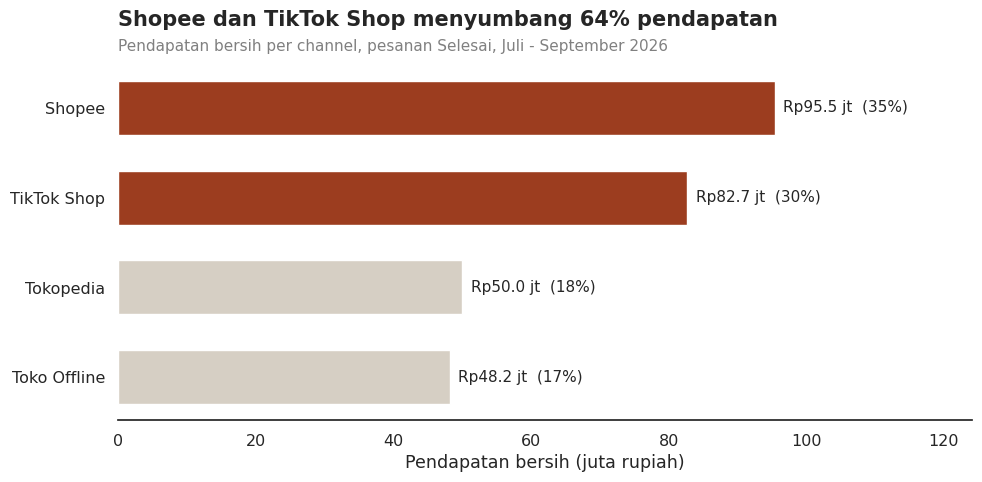

In [ ]:
pendapatan_channel = df_selesai.groupby("channel")["pendapatan_bersih"].sum() / 1_000_000
pendapatan_channel = pendapatan_channel.sort_values()
persen_channel = pendapatan_channel / pendapatan_channel.sum() * 100

# Dua channel teratas disorot, sisanya abu-abu
dua_teratas = pendapatan_channel.index[-2:]
warna = [WARNA_UTAMA if ch in dua_teratas else WARNA_NETRAL for ch in pendapatan_channel.index]
porsi_dua_teratas = persen_channel[dua_teratas].sum()

fig, ax = plt.subplots(figsize=(10, 5))
batang = ax.barh(pendapatan_channel.index, pendapatan_channel.values, color=warna, height=0.6)

label = [f"Rp{nilai:.1f} jt  ({persen:.0f}%)" for nilai, persen in zip(pendapatan_channel, persen_channel)]
ax.bar_label(batang, labels=label, padding=6, fontsize=11)

# Judul berisi temuan, subjudul berisi keterangan data
ax.set_title(f"{dua_teratas[1]} dan {dua_teratas[0]} menyumbang {porsi_dua_teratas:.0f}% pendapatan",
             loc="left", fontsize=15, fontweight="bold", pad=28)
ax.text(0, 1.04, "Pendapatan bersih per channel, pesanan Selesai, Juli - September 2026",
        transform=ax.transAxes, color="gray", fontsize=11)   # transAxes: posisi relatif kotak grafik

ax.set_xlabel("Pendapatan bersih (juta rupiah)")
ax.set_ylabel("")
ax.set_xlim(0, pendapatan_channel.max() * 1.3)
sns.despine(left=True)
plt.tight_layout()
plt.show()

Shopee menghasilkan pendapatan bersih terbesar (Rp95,5 juta) disusul ketat oleh TikTok Shop (Rp82,7 juta), sementara Tokopedia (Rp50,0 juta) dan Toko Offline (Rp48,2 juta) hanya menghasilkan sekitar separuh pendapatan Shopee.

**5.2: line chart, tren harian dan tanggal kembar (P3)**

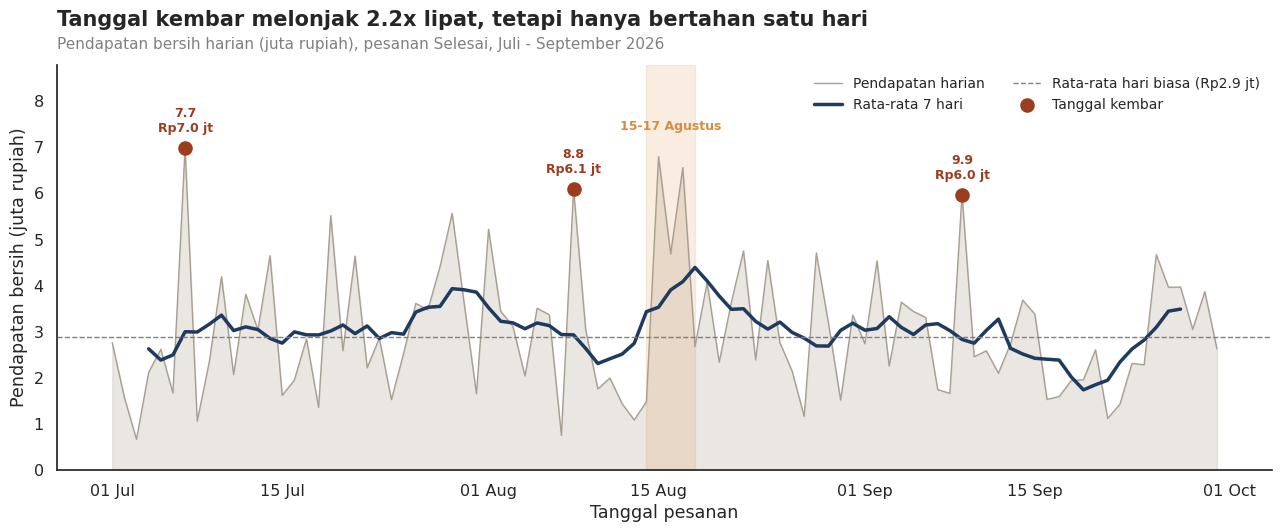

In [ ]:
pendapatan_harian = df_selesai.groupby("tanggal_pesanan")["pendapatan_bersih"].sum() / 1_000_000
rata_7_hari = pendapatan_harian.rolling(7, center=True).mean()

tanggal_kembar = pd.to_datetime(["2026-07-07", "2026-08-08", "2026-09-09"])
pendapatan_kembar = pendapatan_harian[tanggal_kembar]

# Bandingkan rata-rata tanggal kembar dengan rata-rata hari biasa
rata_hari_biasa = pendapatan_harian.drop(tanggal_kembar).mean()
kali_lipat = pendapatan_kembar.mean() / rata_hari_biasa

fig, ax = plt.subplots(figsize=(13, 5.5))

# Area di bawah garis harian + garis rata-rata 7 hari
ax.fill_between(pendapatan_harian.index, pendapatan_harian.values, color=WARNA_NETRAL, alpha=0.5)
ax.plot(pendapatan_harian.index, pendapatan_harian.values, color="#A89F93", linewidth=1, label="Pendapatan harian")
ax.plot(rata_7_hari.index, rata_7_hari.values, color=WARNA_TREN, linewidth=2.5, label="Rata-rata 7 hari")

# Garis putus-putus untuk rata-rata hari biasa
ax.axhline(rata_hari_biasa, color="gray", linestyle="--", linewidth=1,
           label=f"Rata-rata hari biasa (Rp{rata_hari_biasa:.1f} jt)")

# Sorot periode pertengahan Agustus
ax.axvspan(pd.Timestamp("2026-08-14"), pd.Timestamp("2026-08-18"), color=WARNA_KEDUA, alpha=0.15)
ax.text(pd.Timestamp("2026-08-16"), pendapatan_harian.max() + 0.4, "15-17 Agustus",
        ha="center", color=WARNA_KEDUA, fontsize=9, fontweight="bold")

# Titik dan label tanggal kembar
ax.scatter(pendapatan_kembar.index, pendapatan_kembar.values, color=WARNA_UTAMA, s=90, zorder=3, label="Tanggal kembar")
for tanggal, nilai in pendapatan_kembar.items():
    ax.text(tanggal, nilai + 0.35, f"{tanggal.day}.{tanggal.month}\nRp{nilai:.1f} jt",
            ha="center", color=WARNA_UTAMA, fontsize=9, fontweight="bold")

ax.set_title(f"Tanggal kembar melonjak {kali_lipat:.1f}x lipat, tetapi hanya bertahan satu hari",
             loc="left", fontsize=15, fontweight="bold", pad=28)
ax.text(0, 1.04, "Pendapatan bersih harian (juta rupiah), pesanan Selesai, Juli - September 2026",
        transform=ax.transAxes, color="gray", fontsize=11)

ax.set_xlabel("Tanggal pesanan")
ax.set_ylabel("Pendapatan bersih (juta rupiah)")
ax.set_ylim(0, pendapatan_harian.max() + 1.8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))   # format tanggal jadi "15 Aug"
ax.legend(loc="upper right", frameon=False, ncol=2, fontsize=10)
sns.despine()
plt.tight_layout()
plt.show()

Pendapatan di tanggal kembar melonjak sekitar dua kali rata-rata hari biasa (7.7 Rp7,0 juta, 8.8 Rp6,1 juta, 9.9 Rp6,0 juta), tetapi lonjakannya hanya bertahan satu hari, sedangkan kenaikan yang bertahan beberapa hari berturut-turut justru terjadi di pertengahan Agustus sekitar tanggal 15 sampai 17.

**5.3: Grafik bebas (seaborn), item vs pendapatan per kategori (P2)**

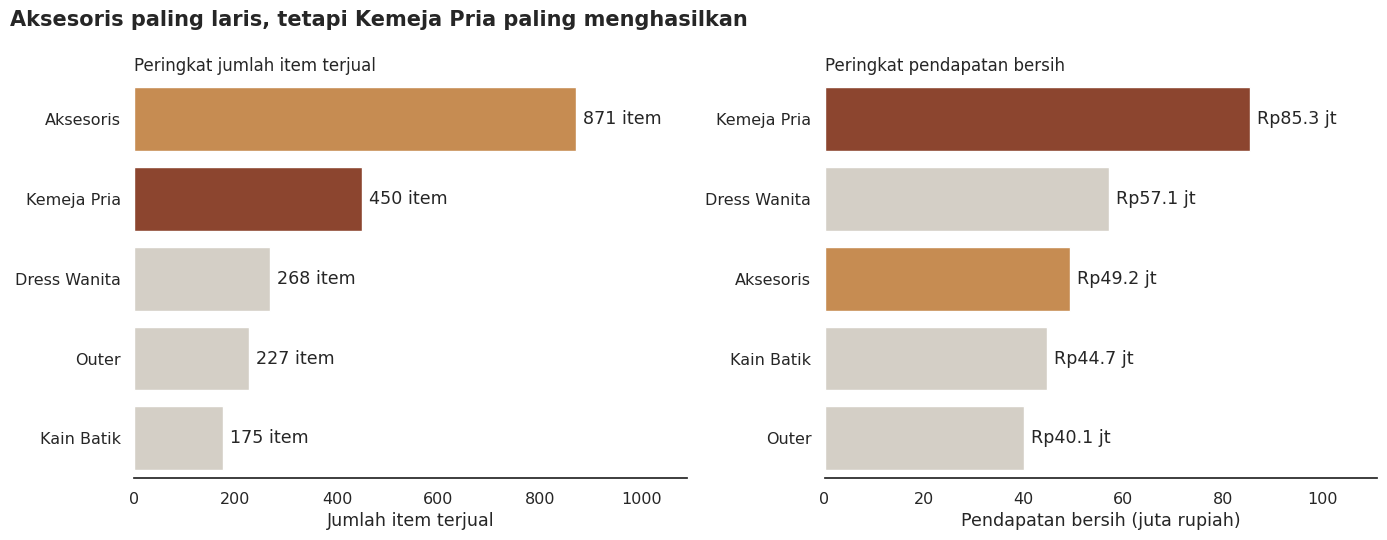

In [ ]:
ringkasan_kategori = df_selesai.groupby("kategori").agg(
    item_terjual=("jumlah", "sum"),
    pendapatan=("pendapatan_bersih", "sum")
).reset_index()
ringkasan_kategori["pendapatan"] = ringkasan_kategori["pendapatan"] / 1_000_000

kategori_terlaris = ringkasan_kategori.loc[ringkasan_kategori["item_terjual"].idxmax(), "kategori"]
kategori_terbesar = ringkasan_kategori.loc[ringkasan_kategori["pendapatan"].idxmax(), "kategori"]

# Warna sama di kedua panel supaya pergeseran peringkat mudah dilacak
warna_kategori = {}
for kategori in ringkasan_kategori["kategori"]:
    if kategori == kategori_terlaris:
        warna_kategori[kategori] = WARNA_KEDUA
    elif kategori == kategori_terbesar:
        warna_kategori[kategori] = WARNA_UTAMA
    else:
        warna_kategori[kategori] = WARNA_NETRAL

urutan_item = ringkasan_kategori.sort_values("item_terjual", ascending=False)["kategori"]
urutan_pendapatan = ringkasan_kategori.sort_values("pendapatan", ascending=False)["kategori"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.barplot(data=ringkasan_kategori, x="item_terjual", y="kategori", hue="kategori",
            order=urutan_item, palette=warna_kategori, legend=False, ax=axes[0])
axes[0].set_title("Peringkat jumlah item terjual", loc="left", fontsize=12)
axes[0].set_xlabel("Jumlah item terjual")
axes[0].set_ylabel("")
axes[0].set_xlim(0, ringkasan_kategori["item_terjual"].max() * 1.25)

sns.barplot(data=ringkasan_kategori, x="pendapatan", y="kategori", hue="kategori",
            order=urutan_pendapatan, palette=warna_kategori, legend=False, ax=axes[1])
axes[1].set_title("Peringkat pendapatan bersih", loc="left", fontsize=12)
axes[1].set_xlabel("Pendapatan bersih (juta rupiah)")
axes[1].set_ylabel("")
axes[1].set_xlim(0, ringkasan_kategori["pendapatan"].max() * 1.3)

# Label angka di setiap batang
for wadah in axes[0].containers:
    axes[0].bar_label(wadah, fmt="%.0f item", padding=5)
for wadah in axes[1].containers:
    axes[1].bar_label(wadah, fmt="Rp%.1f jt", padding=5)

fig.suptitle(f"{kategori_terlaris} paling laris, tetapi {kategori_terbesar} paling menghasilkan",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
sns.despine(left=True)
plt.tight_layout()
plt.show()

Aksesoris paling laris dengan 871 item terjual tetapi hanya berada di peringkat ketiga untuk pendapatan (Rp49,2 juta), sedangkan Kemeja Pria yang terjual 450 item justru memimpin pendapatan (Rp85,3 juta) karena harga per itemnya jauh lebih tinggi.

**5.4: bar chart, persentase pembatalan per metode bayar (P4)**

,count
metode_bayar,
COD,14.60
Paylater,8.82
E-Wallet,4.82
Transfer Bank,3.78
Kartu Debit,0.00
QRIS,0.00
Tunai,0.00


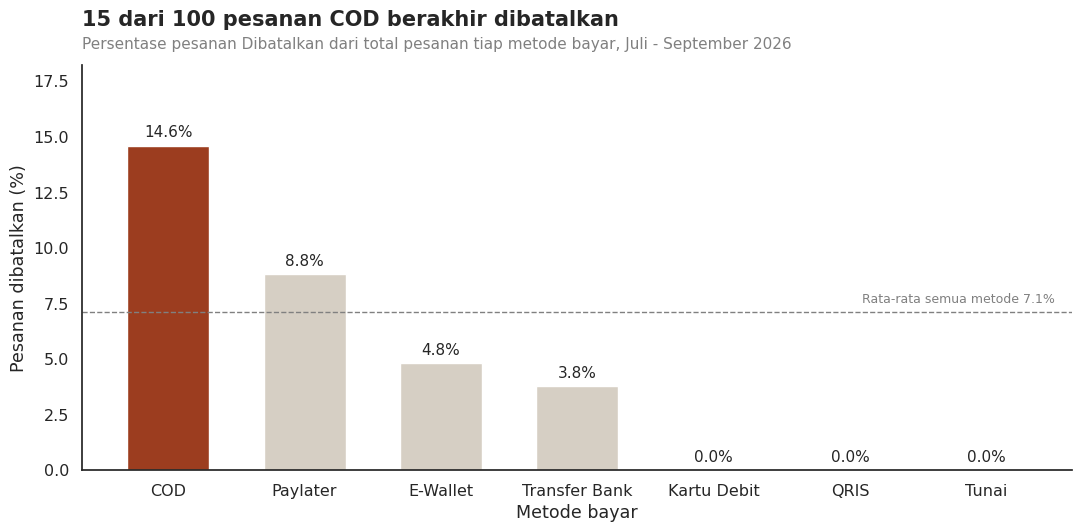

In [ ]:
total_per_metode = df_bersih["metode_bayar"].value_counts()
batal_per_metode = df_bersih[df_bersih["status_pesanan"] == "Dibatalkan"]["metode_bayar"].value_counts()

persen_batal = (batal_per_metode / total_per_metode * 100).fillna(0)
persen_batal = persen_batal.sort_values(ascending=False)
display(persen_batal.round(2))

rata_batal = (df_bersih["status_pesanan"] == "Dibatalkan").mean() * 100
metode_tertinggi = persen_batal.index[0]

warna = [WARNA_UTAMA if metode == metode_tertinggi else WARNA_NETRAL for metode in persen_batal.index]

fig, ax = plt.subplots(figsize=(11, 5.5))
batang = ax.bar(persen_batal.index, persen_batal.values, color=warna, width=0.6)
ax.bar_label(batang, fmt="%.1f%%", padding=4, fontsize=11)

ax.axhline(rata_batal, color="gray", linestyle="--", linewidth=1)
ax.text(len(persen_batal) - 0.5, rata_batal + 0.4, f"Rata-rata semua metode {rata_batal:.1f}%",
        ha="right", color="gray", fontsize=9)

ax.set_title(f"{persen_batal.iloc[0]:.0f} dari 100 pesanan {metode_tertinggi} berakhir dibatalkan",
             loc="left", fontsize=15, fontweight="bold", pad=28)
ax.text(0, 1.04, "Persentase pesanan Dibatalkan dari total pesanan tiap metode bayar, Juli - September 2026",
        transform=ax.transAxes, color="gray", fontsize=11)

ax.set_xlabel("Metode bayar")
ax.set_ylabel("Pesanan dibatalkan (%)")
ax.set_ylim(0, persen_batal.max() * 1.25)
sns.despine()
plt.tight_layout()
plt.show()

COD memiliki tingkat pembatalan tertinggi, yaitu 14.6% dari seluruh pesanan yang memakai metode tersebut, sedangkan QRIS, Kartu Debit, dan Tunai sama sekali tidak memiliki pesanan yang dibatalkan.

# **Insight dan Rekomendasi**

Insight:
1. Channel/platform Shopee dan TikTok Shop menyumbang 64% omzet toko, dengan kontribusi gabungan lebih dari 1,8x lipat dibanding Tokopedia dan Toko Offline. Pesanan terbanyak berasal dari Kota Jakarta.

2. Pendapatan harian Batik Lestari rata-rata sekitar Rp3,0 juta/hari secara keseluruhan, dan sekitar Rp2,9 juta/hari bila tanggal kembar dikecualikan. Namun, omzet melonjak drastis hingga 2,2x lipat khusus pada tanggal kembar (7.7, 8.8, 9.9) dan menjelang Hari Kemerdekaan (15-17 Agustus), dengan produk yang terlaris terjual di tanggal-tanggal kembar tersebut adalah Masker Batik, yang meraih 7.4x lipat penjualan dibandingkan hari-hari biasa.

3. Tingkat pembatalan COD mencapai 14,6% (lebih dari 2x rata-rata metode lain) dan rating kepuasan pelanggan pada kategori pakaian utama (Dress Wanita & Kemeja Pria) masih di bawah rata-rata toko, di mana keduanya memiliki rating 3.94-4.00, sedangkan rating toko secara keseluruhan adalah 4.09.

Rekomendasi:
1. Toko sebaiknya memfokuskan 60% anggarannya untuk iklan digital akhir tahun pada Shopee Ads dan TikTok Ads. Shopee diandalkan untuk konversi penjualan yang stabil, sedangkan TikTok Shop dapat dimanfaatkan untuk mendapat traffic dan content exposure yang besar dalam menarik perhatian para calon pembeli.

2. Lakukan pembatasan opsi COD di marketplace hanya untuk akun-akun pembeli dengan reputasi tingkat sukses pengiriman > 95% untuk meminimalisir pembatalan ataupun pengembalian barang, sehingga tidak akan terjadi kerugian waktu dan tenaga di pihak seller/penjual dan kurir.

3. Lakukan screening ulasan dress wanita dan kemeja pria untuk mencari tau alasan di balik rating rendah di kedua produk tersebut, serta fokuskan investigasi pada ruang ganti dan pelayanan di toko offline Pekalongan, serta visual kamera saat live streaming TikTok.

# **Catatan Penggunaan AI**

Prompt yang dipakai:
- Carilah persebaran kota para pelanggan yang berbelanja di setiap Channel.
- Carilah Top Produk pada tanggal-tanggal kembar & 15-17 Agustus.
- Tampilkan data penjualan Masker Batik Isi 3.
- Bandingkan tingkat penjualan Kemeja Pria saat tanggal-tanggal kembar dan hari besar di Indonesia.
- Bandingkan tingkat penjualan Outer saat tanggal-tanggal kembar dan hari besar di Indonesia.

Bagian yang dibantu AI:
- Pembuatan syntax coding mengenai jumlah produk terjual per tanggal beserta dalam bentuk tabelnya.
- Pembuatan syntax coding untuk menghitung total penjualan pada hari biasa.

Apa yang diganti:
- Kode disesuaikan dengan kode-kode dari section sebelumnya yang telah dibuat (df_bersih)
- Beberapa definisi dan komentar juga direvisi supaya mempermudah pembacaan dan pemahaman kode yang dibuat